# Walkthrough: from gene expression to a web app

This notebook walks through the whole project one stage at a time, using the same code
that `train.py` and `app.py` run (everything is imported from the `sjogrens/` package, so
nothing here is a copy that could drift).

1. **The data**: what's in the CSV, and the bug in the original version
2. **Measuring performance**: why accuracy is misleading here
3. **Leakage**: and how the model's built-in scaling layer avoids it
4. **Cross-validation**: neural network vs. logistic regression
5. **The final model and the web app**: from a trained file to a score on a web page

Run it from the repo root with `uv run jupyter lab notebooks/walkthrough.ipynb`.

In [1]:
import sys
from pathlib import Path

# Make the project folder importable whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_auc_score, roc_curve

from sjogrens import artifacts, config
from sjogrens.data import load_dataset, load_frame
from sjogrens.evaluate import cross_validate, format_summary, out_of_fold_scores, score_metrics, summarize
from sjogrens.model import build_model, predict_scores, train

tf.config.experimental.enable_op_determinism()  # same numbers every run
pd.set_option("display.precision", 3)

## 1. The data

The dataset is a subset of **GEO series GSE66795**: whole-blood gene expression measured on
an Illumina HumanHT-12 v4 microarray, from people with primary Sjögren's syndrome and
healthy controls. Each row is one person. Each gene column is a **log2 intensity**: higher
means the gene is more active in that person's blood cells.

In [2]:
frame = load_frame()
print(f"{len(frame)} samples: {frame.label.sum()} patients, {(frame.label == 0).sum()} controls")
frame.head()

160 samples: 131 patients, 29 controls


,sample_id,label,IRF5,SSB,TRIM21,MX1,IFI44,IFIT1,CD19,TNFSF13B,IL6,CXCL13,FAS,STAT1,AQP5
0,GSM1632237,0,6.801,6.081,9.168,10.998,7.089,7.841,9.688,10.760,6.266,6.107,6.818,9.834,5.750
1,GSM1632238,0,8.455,6.117,9.980,13.408,8.262,9.608,8.661,11.905,6.054,6.126,6.771,11.502,5.807
2,GSM1632239,1,8.818,6.158,8.681,10.119,7.305,7.428,9.647,11.328,6.201,6.081,7.040,9.177,5.847
3,GSM1632240,0,6.668,6.058,9.206,12.305,8.026,9.209,7.936,11.094,6.283,6.138,6.627,10.484,5.805
4,GSM1632241,1,7.651,6.005,9.398,11.190,7.225,8.299,8.604,11.322,6.283,6.121,7.131,10.273,5.967


### What went wrong in the original version

The first version labeled samples with `1 if 'Sjogren' in x else 0`. Look at what the
raw label column actually contains:

In [3]:
raw = pd.read_csv(config.DATA_PATH)
print(raw["Patient Group"].value_counts(), "\n")

old_labels = raw["Patient Group"].apply(lambda x: 1 if "Sjogren" in x else 0)
print("Labels produced by the old rule:", old_labels.value_counts().to_dict())

Patient Group
patient group: Patient    131
patient group: Control     29
Name: count, dtype: int64 

Labels produced by the old rule: {0: 160}


The word "Sjogren" never appears, so **every sample got label 0**. With only one class
the model has nothing to learn, cross-validation couldn't compute an AUC, and the code
fell back to saving an untrained network. Nothing crashed, which is why this kind of
bug is dangerous. `load_frame()` now maps the exact label strings and raises an error
on anything unexpected.

The original also used `Gender` as a feature, but every sample here is female, so it
carries no information (and the web form encoded it the opposite way from training).

### Which genes actually differ between the groups?

A quick check before any machine learning: for each gene, how well does that gene **on
its own** separate patients from controls? The single-gene AUC is the chance that a
random patient has a higher value than a random control (0.5 = no difference).

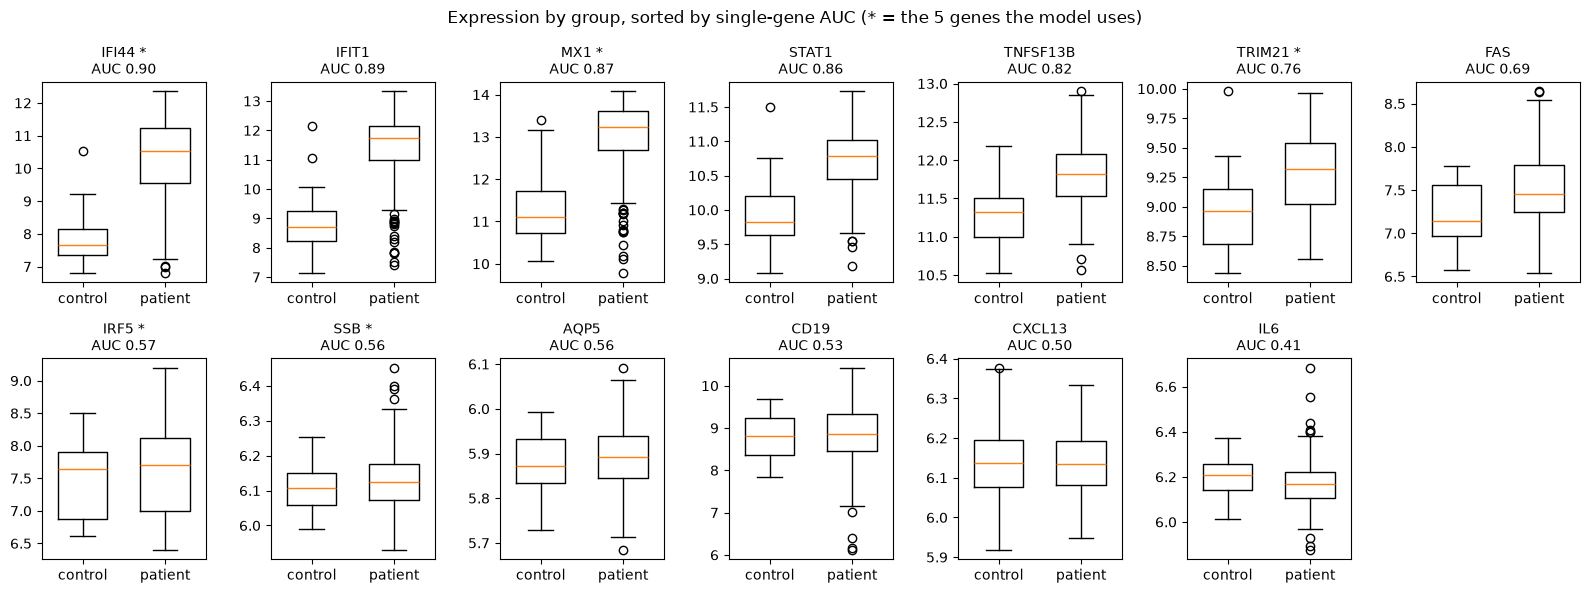

In [4]:
genes = config.ALL_GENES
single_auc = {g: roc_auc_score(frame.label, frame[g]) for g in genes}
order = sorted(genes, key=single_auc.get, reverse=True)

fig, axes = plt.subplots(2, 7, figsize=(16, 6), sharey=False)
for ax, gene in zip(axes.flat, order):
    ax.boxplot([frame.loc[frame.label == 0, gene], frame.loc[frame.label == 1, gene]], widths=0.6)
    ax.set_xticks([1, 2], ["control", "patient"])
    marker = " *" if gene in config.REPORT_GENES else ""
    ax.set_title(f"{gene}{marker}\nAUC {single_auc[gene]:.2f}", fontsize=10)
axes.flat[-1].axis("off")
fig.suptitle("Expression by group, sorted by single-gene AUC (* = the 5 genes the model uses)")
fig.tight_layout()

The strongest genes (IFI44, IFIT1, MX1, STAT1) are all part of the **type I interferon
signature**, a known feature of Sjögren's syndrome. Of the five genes the original
project picked from the literature, MX1 and IFI44 do most of the work, while IRF5 and SSB
barely differ between the groups in this dataset.

The model keeps the original five genes anyway. Choosing genes by looking at this chart
and then testing on the same data would be a form of leakage (section 3): the evaluation
would partly be grading our own peeking. `train.py --features all` runs the 13-gene
version for comparison.

## 2. Measuring performance: why accuracy misleads

82% of the samples are patients, so a "model" that ignores the data and always says
*patient* is right 82% of the time:

In [5]:
X, y = load_dataset()  # the 5 report genes
always_patient = np.ones(len(y))
pd.Series(score_metrics(y, always_patient), name="always guess 'patient'")

roc_auc              0.500
balanced_accuracy    0.500
sensitivity          1.000
specificity          0.000
accuracy             0.819
Name: always guess 'patient', dtype: float64

82% accuracy, yet it never correctly identifies a single control (specificity 0). So the
project reports metrics that can't be gamed this way:

| Metric | Question it answers |
|---|---|
| **ROC AUC** | Pick one patient and one control at random. How often does the patient get the higher score? 0.5 = coin flip. |
| **Sensitivity** | Of the real patients, what share did we flag? |
| **Specificity** | Of the real controls, what share did we clear? |
| **Balanced accuracy** | Average of sensitivity and specificity. |

The training also uses **class weights**: mistakes on the rarer class (controls) count
about 4.5x more in the loss, so the network can't win by always guessing "patient".

## 3. Leakage, and the scaling layer

Neural networks train better when each input is standardized (mean 0, std 1). The
original code fit the scaler on **all 160 samples** and only then split into training
and test folds. That means the test samples influenced the preprocessing. It's a small
effect here, but in general it makes results look better than they really are. Any
information from the test set reaching training counts as **leakage**.

The rebuilt model puts the scaling **inside the network** as a `Normalization` layer.
Calling `build_model(X_train)` makes it learn mean/variance from the training rows only:

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
model = build_model(X_train)
model.summary()

norm = model.get_layer("standardize")
pd.DataFrame(
    {"layer mean": np.ravel(norm.mean.numpy()), "train-split mean": X_train.mean(0), "all-data mean": X.mean(0)},
    index=config.REPORT_GENES,
)

Model: "sjogrens_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ standardize (Normalization)     │ (None, 5)              │            11 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,508 (9.80 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 11 (48.00 B)

,layer mean,train-split mean,all-data mean
IRF5,7.595,7.595,7.597
SSB,6.124,6.124,6.125
TRIM21,9.230,9.230,9.222
MX1,12.668,12.668,12.650
IFI44,9.793,9.793,9.771


The layer's means match the training split, not the full dataset. And since the layer is
part of the model, the saved `models/model.keras` file carries these numbers with it. The
web app feeds in raw values and gets exactly the same preprocessing, with no separate
scaler file to keep in sync.

## 4. Cross-validation: neural network vs. logistic regression

With only 29 controls, a single train/test split is noisy: one unlucky split can swing
the AUC by 0.1. **Stratified k-fold** splits the data into 5 parts that each keep the
82/18 ratio, trains on 4 and tests on the 5th, and rotates. `train.py` repeats that 5
times with different shuffles (25 test folds). Here we do one repeat to keep it quick.

Every fold trains three models on the same split:
- the **neural network**,
- **logistic regression**, a much simpler linear model. If the network can't beat it,
  the extra complexity isn't buying anything,
- the **majority baseline** from section 2.

In [7]:
results = cross_validate(X, y, n_splits=5, n_repeats=1, epochs=100, verbose=False)
print(format_summary(summarize(results)))

                           roc_auc balanced_accuracy    sensitivity    specificity       accuracy
model                                                                                            
neural_net           0.869 ± 0.080     0.825 ± 0.085  0.817 ± 0.067  0.833 ± 0.236  0.819 ± 0.014
logistic_regression  0.901 ± 0.039     0.874 ± 0.047  0.847 ± 0.095  0.900 ± 0.149  0.856 ± 0.057
majority_baseline    0.500 ± 0.000     0.500 ± 0.000  1.000 ± 0.000  0.000 ± 0.000  0.819 ± 0.014


An ROC curve shows the trade-off behind the AUC number. Each point is one possible
threshold: as you flag more people as patients (moving right), you catch more real
patients (up) but also wrongly flag more controls. Here every sample is scored by a model
that never saw it in training:

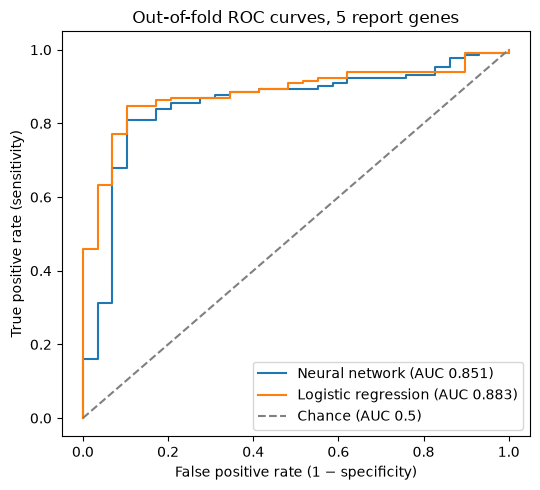

In [8]:
oof = out_of_fold_scores(X, y, n_splits=5, epochs=100)

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, label in [("neural_net", "Neural network"), ("logistic_regression", "Logistic regression")]:
    fpr, tpr, _ = roc_curve(y, oof[name])
    ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(y, oof[name]):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance (AUC 0.5)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("Out-of-fold ROC curves, 5 report genes")
ax.legend(loc="lower right")
fig.tight_layout()

**How to read this:** both models clearly learn real signal (AUC roughly 0.85–0.9). On these 5
genes and 160 samples, the neural network does **not** beat logistic regression. That's
a normal and useful finding. With few samples and a mostly linear relationship (higher
interferon genes → more likely a patient), a simple model is enough. A neural network
pays off with more data or more complex interactions between features.

## 5. The final model and the web app

Cross-validation estimates how well the *recipe* works. The model we actually keep is a
fresh one, trained the same way on **all** 160 samples. The original code kept the
"best" fold's model instead. That model only saw 80% of the data, and was picked partly
for being lucky on its test fold.

`train.py` saves the final model to `models/`. If you haven't run it yet, this cell
trains one (no cross-validation) so the rest of the notebook still works.

In [9]:
loaded = artifacts.load()
if loaded is None:
    print("models/ is empty; training a final model now (same as `train.py --skip-cv`)")
    final = train(X, y)
    artifacts.save(final, artifacts.build_meta(X, y, config.REPORT_GENES, cv_summary=None))
    loaded = artifacts.load()
final_model, meta = loaded

for group in ["patient", "control"]:
    example = meta["examples"][group]
    score = predict_scores(final_model, [[example[g] for g in meta["genes"]]])[0]
    print(f"typical {group:8s} {example}  ->  score {score:.1%}")

typical patient  {'IRF5': 7.709, 'SSB': 6.124, 'TRIM21': 9.316, 'MX1': 13.236, 'IFI44': 10.536}  ->  score 94.6%
typical control  {'IRF5': 7.637, 'SSB': 6.108, 'TRIM21': 8.961, 'MX1': 11.102, 'IFI44': 7.666}  ->  score 15.3%


The web app does exactly this: load the saved model once at startup, read the five
numbers from the form, check them, and call `predict_scores`. Flask's test client can
send the form without starting a server:

In [10]:
import re
from app import create_app

client = create_app().test_client()
response = client.post("/predict", data=meta["examples"]["patient"])
print("HTTP", response.status_code)
print("score shown on page:", re.search(r'class="score"[^>]*>([^<]+)<', response.get_data(as_text=True)).group(1))

bad = client.post("/predict", data={**meta["examples"]["patient"], "MX1": "abc"})
print("bad input -> HTTP", bad.status_code)

HTTP 200
score shown on page: 94.6%
bad input -> HTTP 400


## Recap: the workflow

```
GEO data (CSV)
   │  load_frame / load_dataset      strict label parsing, choose genes
   ▼
X (160 × 5), y (0/1)
   │  cross_validate                 5×5 stratified folds; NN vs logistic regression vs baseline
   ▼
honest performance estimate  ──►  models/meta.json
   │  train (all data)               class weights, scaling layer inside the model
   ▼
models/model.keras
   │  app.py                         load once, validate input, predict_scores
   ▼
score in the browser
```

**Where to go next**
- *External validation:* test on a different cohort. GSE51092 is a natural candidate,
  but it's from a different chip and is missing the IRF5 and SSB probes, so it needs a
  model built on the shared genes and re-normalized values.
- *Calibration:* the score ranks samples well, but "80%" doesn't mean an 80% chance of
  disease. Making that true needs calibration, and above all data with realistic
  disease prevalence.
- *More data:* 29 controls is the biggest limitation. Every metric above has wide error
  bars because of it.